# 03 · Clustering & Evaluasi Model

Di notebook ini kita mengelompokkan **38 provinsi Indonesia** berdasarkan 6 indikator kesiapan digital yang sudah dibersihkan dan dieksplorasi di Notebook 01–02.

Alur pemodelan:
1. **Standardisasi (Z-score)** agar semua fitur punya skala setara.
2. **Penentuan jumlah cluster (`k`)** dengan 4 metrik sekaligus (Elbow/Inertia, Silhouette, Davies-Bouldin, Calinski-Harabasz) + cek distribusi jumlah provinsi.
3. **K-Means (model utama) vs Hierarchical Ward (pembanding)** + ukur tingkat kesepakatan (Adjusted Rand Index).
4. **Visualisasi Dendrogram & PCA 2D** (lengkap dengan interpretasi *loadings*).
5. **Uji Ketahanan (Robustness Check)** terhadap multikolinearitas & outlier temuan Notebook 02.
6. **Simpan hasil cluster** ke `data/processed/provinsi_cluster.csv` untuk tahap profiling & rekomendasi kebijakan di Notebook 04.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler

from src.clustering import agreement, cluster_profile, evaluate_k, fit_kmeans, fit_ward
from src.config import CLUSTER_FILE, FEATURES, INDICATORS, MASTER_FILE, RANDOM_STATE
from src.preprocessing import scale_features
from src.visualization import save_matplotlib

sns.set_theme(style="whitegrid")

df = pd.read_csv(MASTER_FILE).dropna(subset=FEATURES).reset_index(drop=True)
X, scaler = scale_features(df, FEATURES)

print(f"Data siap clustering: {X.shape[0]} provinsi x {X.shape[1]} fitur")
print("\nCek hasil z-score (mean harus ~0, std harus ~1):")
X.agg(["mean", "std", "min", "max"]).round(2)

Data siap clustering: 38 provinsi x 6 fitur

Cek hasil z-score (mean harus ~0, std harus ~1):


,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls
mean,-0.00,0.00,-0.00,-0.00,0.00,0.00
std,1.01,1.01,1.01,1.01,1.01,1.01
min,-4.15,-4.13,-2.71,-3.83,-4.36,-3.88
max,1.30,1.38,2.79,0.85,0.52,2.05


**Kenapa wajib standardisasi (z-score)?**
- `rls` berskala 4–12 tahun, sedangkan 5 indikator lain berskala 0–100%. Tanpa z-score, perhitungan jarak Euclidean pada K-Means akan didominasi indikator dengan rentang angka besar (`pct_desa_4g`, `pct_skill_tik`) dan hampir mengabaikan `rls`.

## 1. Penentuan Jumlah Cluster (`k` = 2 sampai 8)
Kita tidak mengandalkan satu metrik saja, melainkan membandingkan 4 indikator evaluasi:
- **Inertia (Elbow):** semakin kecil semakin rapat; cari titik "siku" saat penurunannya mulai melandai.
- **Silhouette Score:** semakin **tinggi** (mendekati 1) semakin terpisah tegas antar cluster.
- **Davies-Bouldin Index (DBI):** semakin **rendah** (mendekati 0) semakin baik.
- **Calinski-Harabasz Index:** semakin **tinggi** semakin baik.

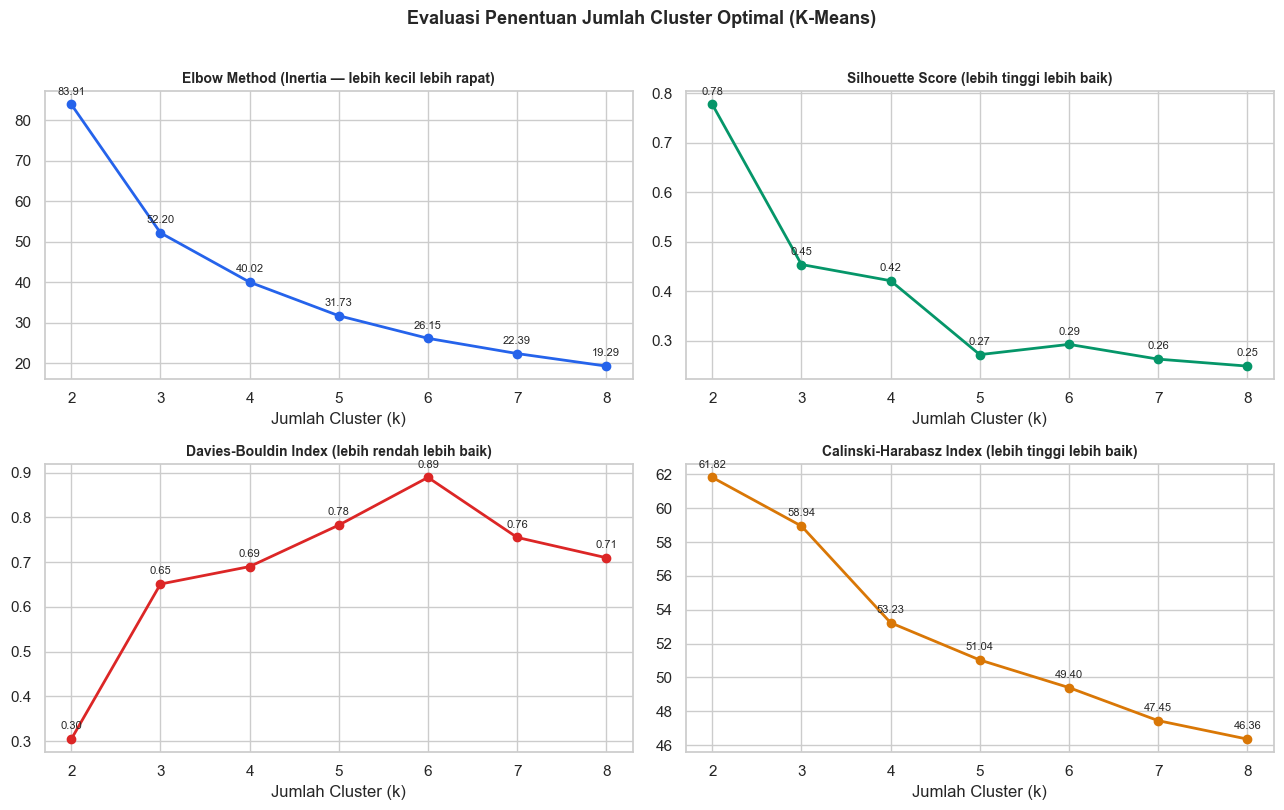

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,83.912,0.777,0.304,61.817
1,3,52.196,0.454,0.651,58.943
2,4,40.021,0.421,0.690,53.232
3,5,31.728,0.272,0.783,51.035
4,6,26.149,0.293,0.889,49.404
5,7,22.387,0.263,0.755,47.453
6,8,19.293,0.249,0.710,46.363


In [2]:
scores = evaluate_k(X, k_range=range(2, 9))

metrics = [
    ("inertia", "Elbow Method (Inertia — lebih kecil lebih rapat)", "#2563eb"),
    ("silhouette", "Silhouette Score (lebih tinggi lebih baik)", "#059669"),
    ("davies_bouldin", "Davies-Bouldin Index (lebih rendah lebih baik)", "#dc2626"),
    ("calinski_harabasz", "Calinski-Harabasz Index (lebih tinggi lebih baik)", "#d97706"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, title, color) in zip(axes.flat, metrics):
    ax.plot(scores["k"], scores[col], marker="o", linewidth=2, color=color)
    for k_val, y_val in zip(scores["k"], scores[col]):
        ax.annotate(f"{y_val:.2f}", (k_val, y_val), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xlabel("Jumlah Cluster (k)")
    ax.set_xticks(scores["k"])

fig.suptitle("Evaluasi Penentuan Jumlah Cluster Optimal (K-Means)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
save_matplotlib(fig, "03_penentuan_k")
plt.show()

scores.round(3)

## 2. Cek Keseimbangan Anggota untuk Kandidat `k = 2, 3, 4, 5`
Dalam data yang punya outlier ekstrem (seperti Papua Pegunungan & Papua Tengah di Notebook 02), `k = 2` sering mendapat skor Silhouette tertinggi hanya karena memisahkan 2 provinsi ekstrem vs 36 provinsi lainnya. Cell ini mengecek distribusi ukuran tiap cluster agar kita memilih `k` yang **baik secara statistik sekaligus bermakna untuk kebijakan**.

In [3]:
k_summary = []
for k_cand in [2, 3, 4, 5]:
    km_cand = fit_kmeans(X, k_cand)
    _, ward_cand = fit_ward(X, k_cand)
    counts = pd.Series(km_cand.labels_).value_counts().sort_values(ascending=False).tolist()
    row_score = scores.loc[scores["k"] == k_cand].iloc[0]
    k_summary.append({
        "k": k_cand,
        "ukuran_cluster": counts,
        "silhouette": round(row_score["silhouette"], 3),
        "davies_bouldin": round(row_score["davies_bouldin"], 3),
        "ARI_vs_Ward": round(agreement(km_cand.labels_, ward_cand), 3),
    })

pd.DataFrame(k_summary)

,k,ukuran_cluster,silhouette,davies_bouldin,ARI_vs_Ward
0,2,"[36, 2]",0.777,0.304,1.000
1,3,"[30, 6, 2]",0.454,0.651,0.889
2,4,"[28, 6, 2, 2]",0.421,0.690,0.815
3,5,"[19, 12, 4, 2, 1]",0.272,0.783,0.599


**Cara membaca tabel perbandingan `k` di atas:**
- Perhatikan kolom `ukuran_cluster`: jika `k = 2` menghasilkan `[36, 2]`, artinya 36 provinsi dari DKI Jakarta sampai NTT dicampur dalam satu kelompok — terlalu kasar untuk rekomendasi kebijakan.
- Pilih `k` (default di bawah `K = 4`) yang memisahkan kelompok maju, menengah/transisi, dan tertinggal secara jelas dengan `ARI_vs_Ward` tetap kuat. Kamu bisa mengubah angka `K` di cell berikut jika ingin mencoba `k = 3` atau `k = 5`.

## 3. Model Utama (K-Means) & Pembanding (Hierarchical Ward)
Kita jalankan K-Means dengan `K = 4`, lalu **mengurutkan ulang nomor cluster** berdasarkan skor rata-rata z-score (dari `0` = paling tinggi/maju sampai `K-1` = paling rendah/tertinggal) agar penomoran konsisten. Setelah itu kita ukur kecocokan dengan Hierarchical Ward lewat **Adjusted Rand Index (ARI)** dan tabel silang (`crosstab`).

In [4]:
K = 4  # Ubah jika setelah melihat tabel di atas kamu ingin memilih k lain

km = fit_kmeans(X, K)
Z, ward_raw = fit_ward(X, K)

# Urutkan ulang nomor cluster: 0 = rata-rata z-score tertinggi, K-1 = terendah
def reorder_labels(labels, X_scaled):
    order = X_scaled.assign(_lbl=labels).groupby("_lbl").mean().mean(axis=1).sort_values(ascending=False).index
    mapping = {old: new for new, old in enumerate(order)}
    return pd.Series(labels).map(mapping).to_numpy()

df["cluster"] = reorder_labels(km.labels_, X)
df["cluster_ward"] = reorder_labels(ward_raw, X)

ari_ward = agreement(df["cluster"], df["cluster_ward"])
print(f"Jumlah cluster (K)   : {K}")
print(f"ARI K-Means vs Ward  : {ari_ward:.3f}  (1.0 = identik, >0.7 = sangat konsisten)")

print("\nTabel silang K-Means (baris) vs Hierarchical Ward (kolom):")
display(pd.crosstab(df["cluster"], df["cluster_ward"], margins=True))

print("\nDaftar anggota tiap cluster (K-Means):")
for c, grp in df.groupby("cluster"):
    print(f"Cluster {c} ({len(grp)} provinsi): {', '.join(grp['provinsi'].tolist())}")

Jumlah cluster (K)   : 4
ARI K-Means vs Ward  : 0.815  (1.0 = identik, >0.7 = sangat konsisten)

Tabel silang K-Means (baris) vs Hierarchical Ward (kolom):


cluster_ward,0,1,2,3,All
cluster,,,,,
0,5,1,0,0,6
1,0,28,0,0,28
2,0,1,1,0,2
3,0,0,0,2,2
All,5,30,1,2,38



Daftar anggota tiap cluster (K-Means):
Cluster 0 (6 provinsi): Kepulauan Riau, DKI Jakarta, DI Yogyakarta, Bali, Kalimantan Timur, Kalimantan Utara
Cluster 1 (28 provinsi): Aceh, Sumatera Utara, Sumatera Barat, Riau, Jambi, Sumatera Selatan, Bengkulu, Lampung, Kepulauan Bangka Belitung, Jawa Barat, Jawa Tengah, Jawa Timur, Banten, Nusa Tenggara Barat, Kalimantan Barat, Kalimantan Tengah, Kalimantan Selatan, Sulawesi Utara, Sulawesi Tengah, Sulawesi Selatan, Sulawesi Tenggara, Gorontalo, Sulawesi Barat, Maluku, Maluku Utara, Papua Barat, Papua Barat Daya, Papua
Cluster 2 (2 provinsi): Nusa Tenggara Timur, Papua Selatan
Cluster 3 (2 provinsi): Papua Tengah, Papua Pegunungan


## 4. Dendrogram (Hierarchical Ward)
Dendrogram menunjukkan hierarki kedekatan ke-38 provinsi secara berjenjang. Garis putus-putus horizontal menandai batas pemotongan tepat pada `K` cluster sehingga kita bisa melihat provinsi mana yang paling mirip satu sama lain dan mana yang terpisah paling jauh.

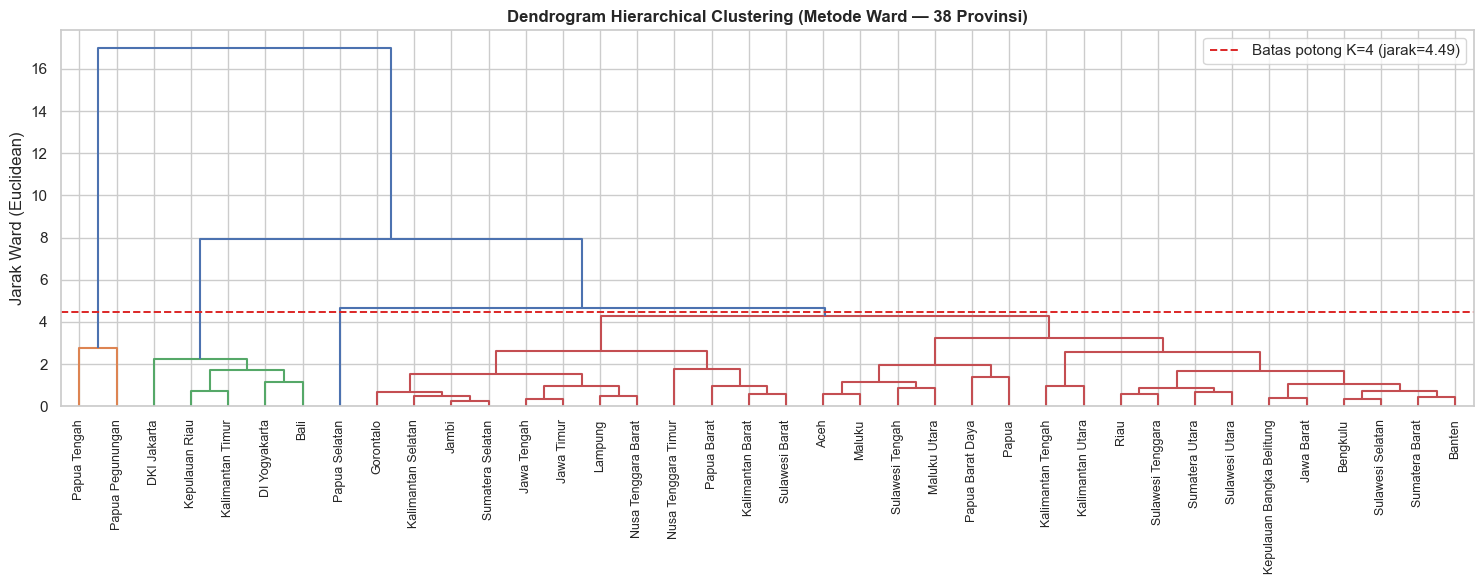

In [5]:
cut_height = (Z[-(K - 1), 2] + Z[-K, 2]) / 2

fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(
    Z,
    labels=df["provinsi"].tolist(),
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=cut_height,
    ax=ax,
)
ax.axhline(cut_height, color="#dc2626", linestyle="--", linewidth=1.4, label=f"Batas potong K={K} (jarak={cut_height:.2f})")
ax.set_title("Dendrogram Hierarchical Clustering (Metode Ward — 38 Provinsi)", fontsize=12, fontweight="bold")
ax.set_ylabel("Jarak Ward (Euclidean)")
ax.legend(loc="upper right")

plt.tight_layout()
save_matplotlib(fig, "03_dendrogram")
plt.show()

## 5. Visualisasi Cluster pada Ruang PCA 2D
Karena kita punya 6 dimensi indikator, kita proyeksikan ke 2 dimensi utama (**PC1** dan **PC2**) menggunakan **PCA** agar hasil cluster bisa dilihat secara visual. Kita juga mencetak tabel **PCA loadings** agar jelas indikator apa yang paling membentuk sumbu X (PC1) dan sumbu Y (PC2).

Variansi terjelaskan: PC1=82.1%, PC2=10.2%, Total=92.4%

Kontribusi tiap indikator (PCA Loadings):


,PC1,PC2
pct_internet,0.436,-0.145
pct_hp,0.436,0.030
pct_komputer,0.364,0.697
pct_desa_4g,0.387,-0.440
pct_skill_tik,0.418,-0.418
rls,0.403,0.351


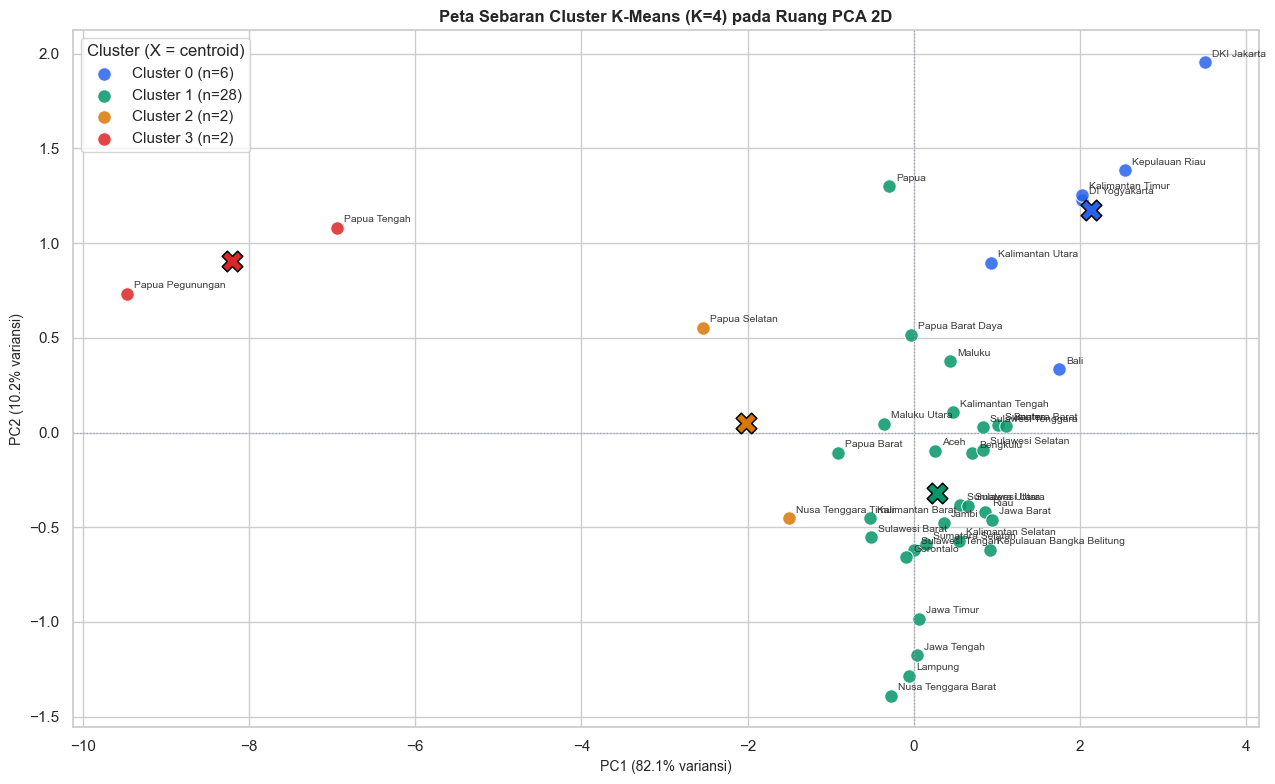

In [6]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X)
df["pc1"] = coords[:, 0]
df["pc2"] = coords[:, 1]

var_ratio = pca.explained_variance_ratio_
print(f"Variansi terjelaskan: PC1={var_ratio[0]*100:.1f}%, PC2={var_ratio[1]*100:.1f}%, Total={var_ratio.sum()*100:.1f}%")

loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(3)
print("\nKontribusi tiap indikator (PCA Loadings):")
display(loadings)

palette = ["#2563eb", "#059669", "#d97706", "#dc2626", "#7c3aed", "#0891b2"][:K]
fig, ax = plt.subplots(figsize=(13, 8))
for c in range(K):
    sub = df[df["cluster"] == c]
    ax.scatter(sub["pc1"], sub["pc2"], s=95, color=palette[c], label=f"Cluster {c} (n={len(sub)})",
               alpha=0.85, edgecolor="white", linewidth=0.8)
    # Tandai pusat cluster di ruang PCA
    ax.scatter(sub["pc1"].mean(), sub["pc2"].mean(), s=220, color=palette[c],
               marker="X", edgecolor="black", linewidth=1.1, zorder=5)

for _, row in df.iterrows():
    ax.annotate(row["provinsi"], (row["pc1"], row["pc2"]), xytext=(5, 4),
                textcoords="offset points", fontsize=7.5, alpha=0.9)

ax.axhline(0, color="#9ca3af", linestyle=":", linewidth=0.9)
ax.axvline(0, color="#9ca3af", linestyle=":", linewidth=0.9)
ax.set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}% variansi)", fontsize=10)
ax.set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}% variansi)", fontsize=10)
ax.set_title(f"Peta Sebaran Cluster K-Means (K={K}) pada Ruang PCA 2D", fontsize=12, fontweight="bold")
ax.legend(title="Cluster (X = centroid)", loc="best")

plt.tight_layout()
save_matplotlib(fig, "03_pca_clusters")
plt.show()

## 6. Uji Ketahanan (Robustness Check)
Di Notebook 02 kita menemukan dua catatan penting: (1) korelasi Pearson tinggi pada beberapa pasangan fitur, dan (2) adanya outlier ekstrem (Papua Pegunungan, Papua Tengah, DKI Jakarta). Cell ini menguji apakah hasil cluster tetap konsisten jika kita:
1. **Clustering di ruang PCA (95% variansi)** untuk menghilangkan efek multikolinearitas.
2. **Mengganti standardisasi ke `RobustScaler`** (berbasis median & IQR, lebih kebal outlier).
3. **Menguji `K-Medoids`** (jika kompatibel di environment lokal) sebagai algoritma yang menggunakan titik asli (*medoid*) alih-alih rata-rata (*centroid*).

In [7]:
robust_rows = [
    {"pembanding": "Hierarchical Ward (StandardScaler)", "ARI_vs_KMeans": round(ari_ward, 3)},
]

# 1. Cek sensitivitas multikolinearitas: K-Means di ruang PCA (95% variance)
X_pca95 = PCA(n_components=0.95, random_state=RANDOM_STATE).fit_transform(X)
km_pca = fit_kmeans(X_pca95, K)
robust_rows.append({
    "pembanding": f"K-Means pada PCA 95% ({X_pca95.shape[1]} komponen)",
    "ARI_vs_KMeans": round(agreement(df["cluster"], km_pca.labels_), 3),
})

# 2. Cek sensitivitas outlier: K-Means dengan RobustScaler (median & IQR)
X_robust = RobustScaler().fit_transform(df[FEATURES])
km_robust = fit_kmeans(X_robust, K)
robust_rows.append({
    "pembanding": "K-Means (RobustScaler / tahan outlier)",
    "ARI_vs_KMeans": round(agreement(df["cluster"], km_robust.labels_), 3),
})

# 3. Opsional: K-Medoids (jika scikit-learn-extra kompatibel dengan NumPy saat ini)
try:
    from sklearn_extra.cluster import KMedoids
    kmed = KMedoids(n_clusters=K, random_state=RANDOM_STATE).fit(X)
    robust_rows.append({
        "pembanding": "K-Medoids (StandardScaler)",
        "ARI_vs_KMeans": round(agreement(df["cluster"], kmed.labels_), 3),
    })
except Exception as exc:
    print(f"Catatan: K-Medoids dilewati ({type(exc).__name__}: {exc})")

pd.DataFrame(robust_rows)

Catatan: K-Medoids dilewati (ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject)


,pembanding,ARI_vs_KMeans
0,Hierarchical Ward (StandardScaler),0.815
1,K-Means pada PCA 95% (3 komponen),0.709
2,K-Means (RobustScaler / tahan outlier),0.244


## 7. Profil Singkat & Simpan Hasil ke `data/processed/provinsi_cluster.csv`
Kita tampilkan rata-rata awal tiap indikator per cluster dan simpan hasilnya agar bisa dianalisis lebih dalam (radar chart, penamaan cluster, analisis paradoks, dan rekomendasi kebijakan) di **Notebook 04**.

In [8]:
prof = cluster_profile(df, FEATURES, label_col="cluster").round(2)
display(prof)

df.to_csv(CLUSTER_FILE, index=False)
print(f"Hasil clustering berhasil disimpan ke: {CLUSTER_FILE}")
print(f"Ukuran file output: {df.shape[0]} provinsi x {df.shape[1]} kolom")

,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls,n_provinsi
cluster,,,,,,,
0,85.30,80.08,31.36,89.39,98.46,10.48,6
1,75.33,70.52,18.84,89.33,94.95,9.24,28
2,56.46,53.32,16.44,84.60,71.95,8.50,2
3,24.02,29.92,4.49,20.24,26.42,5.22,2


Hasil clustering berhasil disimpan ke: C:\Users\USER\Documents\indonesia_digital_divide_clustering\data\processed\provinsi_cluster.csv
Ukuran file output: 38 provinsi x 11 kolom


## 8. Ringkasan Pemodelan

### Q&A
- **Mengapa tidak otomatis memakai `k = 2` meski Silhouette-nya tinggi?** Karena dengan adanya outlier ekstrem di Papua Pegunungan dan Papua Tengah, `k = 2` cenderung hanya memisahkan 2 provinsi tersebut dari 36 provinsi lainnya. Memilih `k` yang seimbang secara statistik sekaligus membedakan jenjang kesiapan digital (misal `K = 4`) jauh lebih berguna untuk intervensi kebijakan.

### Data Analysis Key Findings
- Seluruh 38 provinsi telah distandardisasi dengan z-score dan dikelompokkan dengan K-Means (`cluster 0` teratas hingga `cluster K-1` terbawah).
- Konsistensi hasil telah diuji silang terhadap Hierarchical Ward, reduksi PCA 95%, dan `RobustScaler` menggunakan Adjusted Rand Index (ARI).
- Visualisasi evaluasi `k`, dendrogram Ward, dan proyeksi PCA 2D telah tersimpan 300 DPI di `reports/figures/`.

### Insights or Next Steps
- Periksa output tabel perbandingan `k`, nilai ARI, dan profil rata-rata tiap cluster di atas. Jika ingin mencoba jumlah cluster lain (misal `K = 3` atau `K = 5`), cukup ubah nilai `K` di Cell 4 lalu jalankan ulang ke bawah.
- Lanjut ke **Notebook 04 (`04_profiling_policy.ipynb`)** untuk memvisualisasikan radar chart per cluster, memberi nama tipologi wilayah digital, membedah provinsi paradoks, dan menyusun matriks rekomendasi kebijakan.